# Automatic Encoding for the Iceberg Architecture using Nexus Console

**Download this notebook - {nb-download}`iceberg_encoding.ipynb`**


```{note}
This feature will become available to Nexus Console users in the 26.2 release of the Quantinuum Nexus developer platform.

The release notes for the platform releases can be found [here](https://docs.quantinuum.com/platform/releases/).
```

We have seen in the [Steane code example](https://docs.quantinuum.com/guppy/ft/examples/steane_encoding.html) that Guppy FT provides automatic encoding for Guppy programs. In this demonstration, we will show automatic encoding for the $[[k+2, k, 2]]$ Iceberg architecture. The Iceberg code is distance $2$ so it can detect (but not correct) an arbitrary single qubit error. Once an error is detected, it is possible to exit the program early, skipping any remaining gates.

Unlike Steane, encoding a program with the Iceberg architecture requires the use of Nexus Console - Quantinuum's cloud platform. As Nexus Console is required, we will need the [qnexus](https://github.com/Quantinuum/qnexus) client package. The workflow is comprised of three steps.

1. Write a computational program in Guppy. A computational program can be written independently of QEC or fault-tolerance. We then compile this program. 
2. Secondly, define some Iceberg encoding parameters via the {py:class}`~guppyft.code.iceberg.encode.IcebergBuilder` class. These parameters will include the number of logical qubits in a block, the number of blocks and a policy for inserting quantum error detection (QED) cycles.
3. Finally, upload the annotated program to Nexus Console. Compilation to the physical gates will happen server-side. The program will then be executed on a quantum device or simulator.

## Setup

The `qnexus` Python package can be installed as follows
```shell
pip install qnexus
```

In addition, we will also need a Nexus Console account. If you don't already have access to Nexus Console, it is possible to apply for access at https://nexus.quantinuum.com/signup.

Once we have the `qnexus` package installed, we can log in to Nexus Console and create a project to keep track of all of the jobs we run.

In [ ]:
import qnexus as qnx

qnx.login()

project = qnx.projects.get_or_create(name="iceberg_project")
qnx.context.set_active_project(project)

Already logged in. Tokens are valid.


## Write a computational program

We can now define our computational program using Guppy. For demonstration purposes, we will show a $k$ qubit Quantum Fourier Transform ($QFT$) followed by an $X$-basis measurement of all of the logical qubits. The expected result in the absence of errors would be the state $|0\rangle^{\otimes k}$. This is true as the action of $QFT$ on the $|0\rangle^{\otimes k}$ state is the same as the Hadamard transform.

$$
QFT |0 \rangle ^{\otimes k} = |+\rangle^{\otimes{k}}
$$

The $k$ qubit $QFT$ can be implemented with $k$ Hadamard gates and $\frac{k(k-1)}{2}$ controlled rotations. Given the quadratic number of two qubit gates, the program is deep enough for errors to occur if we run it with a noise model. This will serve to demonstrate a QED policy (see next section). It's also very easy to see which shots give the expected result of $|0\rangle^{\otimes k}$ and which shots are discarded after an error is detected.

In [44]:
from guppylang import guppy
from guppylang.std.builtins import array, nat
from guppylang.std.quantum import h, crz, qubit, rz
from guppylang.std.angles import pi, angle
from guppylang.std.mem import mem_swap


@guppy
def cphase(control: qubit, target: qubit, theta: angle) -> None:
    rz(control, theta / 2)
    crz(control, target, theta)

@guppy
def qft[k: nat](qs: array[qubit, k]) -> None:
    for i in range(k):
        h(qs[i])
        for j in range(i + 1, k):
            cphase(qs[j], qs[i], pi / 2 ** (j - i))

    # Reverse qubit order with swaps
    for m in range(k // 2):
        mem_swap(qs[m], qs[k - m - 1])

Now that we have our $QFT$ implementation, lets define a helper to measure an array of $k$ qubits in the $X$-basis.

In [45]:
from guppylang.std.builtins import owned
from guppylang.std.quantum import Measurement, measure_array

@guppy
def measure_x_array[k: nat](qs: array[qubit, k] @ owned) -> array[Measurement, k]:
    for i in range(k):
        h(qs[i])
    return measure_array(qs)

We also need a `main` function which defines the entrypoint to our quantum program. inside this `main` function we first allocate some qubits before applying the $QFT$ followed by a layer of Hadamard gates. Finally, we measure all of the qubits.

In [46]:
from guppylang.std.platform import output
from guppylang.std.quantum import collect_measurements
from guppylang.defs import GuppyFunctionDefinition


def build_qft_main(num_logical_qubits: int) -> GuppyFunctionDefinition:
    @guppy
    def main() -> None:
        qs = array(qubit() for _ in range(num_logical_qubits))
        qft(qs)
        measurements = measure_x_array(qs)
        output("m_x", collect_measurements(measurements))

    return main

We can now create $k=6$ qubit instance of our $QFT$ program and compile it to the HUGR intermediate representation.

In [47]:
n_qft_qubits = 6

qft_main = build_qft_main(n_qft_qubits)
pkg = qft_main.compile()

## Define Iceberg encoding parameters

Now that we have our computational program, we can use the {py:class}`~guppyft.code.iceberg.encode.IcebergBuilder` to configure the parameters of the Iceberg architecture. 

The {py:class}`~guppyft.code.iceberg.encode.IcebergBuilder` should be configured with an {py:class}`~guppyft.code.iceberg.encode.IcebergQEDPolicy`---a policy describing when quantum error detection (QED) cycles should be applied. Guppy FT allows users to assign different costs to logical operations. These costs are accumulated as the program runs, and a QED cycle is inserted whenever the user defined threshold is reached.


For our policy we will choose to assign a equal cost of `1.0` to Hadamard and ZZPhase gates. A QED cycle will be performed after a threshold value of 10 is met. Note that the controlled rotation gates in the $QFT$ implementation will be compiled in terms of ZZPhase and single qubit gates.

In [48]:
from guppyft.code.iceberg.encode import IcebergBuilder, IcebergQEDPolicy


qed_policy = IcebergQEDPolicy()

qed_policy.costs.h_all = 1.0
qed_policy.costs.zz_phase_intrablock = 1.0

# Insert a QED cycle after 10 gates are applied
qed_policy.threshold = 10

Once we have defined a policy, we can use the {py:class}`~guppyft.code.iceberg.encode.IcebergBuilder` to annotate our compiled Guppy program with some metadata which stores all of the encoding parameters that we have specified. Computational to physical compilation can then be done server-side.

For this example we are going to our encode our 6 qubit $QFT$ program in a single $[[8, 6, 2]]$ Iceberg block.

In [49]:
# Specify the block size (number of logical qubits) and number of blocks
n_blocks = 1

iceberg_instance = (
    IcebergBuilder.new(block_size=n_qft_qubits, n_blocks=n_blocks)
    .with_qed_policy(qed_policy)
    .build()
)

# Annotate block_size, n_blocks, qed_policy and other parameters onto the compiled program.
iceberg_instance.annotate(pkg)

## Upload to Nexus Console for execution

We can now upload our $QFT$ program to the cloud using the `qnexus` client for compilation and execution. This program is now annotated with all of the Iceberg parameters that we specified in the previous section. 

In [50]:
import uuid

name = f"iceberg-nexus-{uuid.uuid4()}"
iceberg_hugr_ref = qnx.hugr.upload(hugr_package=pkg, name=name)

In this example, we submit for execution on the `Helios-1E` remote emulator. This emulator uses a physics informed noise model to mimic the noise present in the Quantinuum Helios-1 device.

In [51]:
config = qnx.HeliosConfig(
    system_name="Helios-1E", emulator_config=qnx.models.HeliosEmulatorConfig()
)

Finally, we submit an execute job to run on the `Helios-1E` emulator by passing a reference to our Iceberg-annotated program to the `qnx.start_execute_job` method. Note how we have to specify the `max_cost` in HQCs and also specify a total number of physical qubits to be used in the simulation.

In general, it is not straightforward to predict the number of qubits needed by the physical program. We need at least 8 qubits for the $[[8, 6, 2]]$ block, but the Iceberg architecture requires additional ancilla qubits for state preparation and error detection. We choose to set an upper bound of 16 physical qubits to allow plenty of ancilla qubits during runtime. We will execute this encoded $QFT$ program on the noisy emulator for 500 shots.


```{note}
Before running encoded programs it's highly recommended to test the program with the coinflip or classical replay simulators. This can help determine the number of physical qubits used at runtime and potentially detect issues which could otherwise manifest as runtime errors.

See the [Nexus console docs](https://docs.quantinuum.com/nexus/trainings/notebooks/basics/selene_examples.html#coinflip-simulation) for information on how to use the coinflip and classical replay simulations. 
```

In [52]:
ref_execute_job = qnx.start_execute_job(
    programs=[iceberg_hugr_ref],
    n_shots=[500],
    backend_config=config,
    max_cost=1000,
    name=f"Iceberg QFT-(n_logical_qubits={n_qft_qubits}, n_blocks={n_blocks})",
    n_qubits=16,
)

## Analyze the results

Now that we have finished running our Iceberg experiment, we can download our results from Nexus Console and analyze them.

In [53]:
qnx.jobs.wait_for(ref_execute_job)
results = qnx.jobs.results(ref_execute_job)
result_ref = results[0]
sys_result = result_ref.download_result()

Firstly, we will plot the proportion of completed shots as a fraction of the total number of shots. This will allow us to clearly see how many shots exit when an error is detected. Of the completed shots, some of them will not the the expected "all $|0\rangle$" state. These shots represent undetected errors.

In [54]:
import matplotlib.pyplot as plt
from guppylang.emulator.result import QsysResult
from matplotlib.ticker import PercentFormatter


def _qft_axes(title: str, ylabel: str, width: float):
    _, ax = plt.subplots(figsize=(width, 4), constrained_layout=True)
    ax.set(title=f"Iceberg-encoded QFT · {title}", ylabel=ylabel)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    return ax


def plot_exit_proportion(sys_result: QsysResult) -> None:
    collated = sys_result.collated_counts()
    total = sum(collated.values())
    if not total:
        return

    early = collated[()]
    completed = total - early
    counts = sys_result.register_counts().get("m_x", {})
    all_zero = sum(n for state, n in counts.items() if state and set(state) == {"0"})
    errors = completed - all_zero

    ax = _qft_axes("Early exits and completed shots", "Share of all shots", width=7)
    early_bar = ax.bar("Early exit", early / total, color="0.55", width=0.55)
    ax.bar_label(early_bar, labels=[f"{early / total:.1%}"], padding=4)

    if completed:
        ax.bar(
            "Completed", all_zero / total, color="tab:blue", width=0.55,
            label=rf"$|0\cdots0\rangle$ · {all_zero / completed:.1%} ({all_zero:,})",
        )
        error_bar = ax.bar(
            "Completed", errors / total, bottom=all_zero / total,
            color="tab:orange", width=0.55,
            label=f"Undetected error · {errors / completed:.1%} ({errors:,})",
        )
        ax.legend(title="Among completed shots", frameon=False,
                  loc="upper center", bbox_to_anchor=(0.5, -0.12))
        ax.bar_label(error_bar, labels=[f"{completed / total:.1%}"], padding=4)
    else:
        ax.bar("Completed", 0, color="tab:blue", width=0.55)
        ax.annotate("0.0%", ("Completed", 0), xytext=(0, 4),
                    textcoords="offset points", ha="center")

    ax.set(ylim=(0, 1.10), yticks=[0, 0.25, 0.50, 0.75, 1])
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    plt.show()

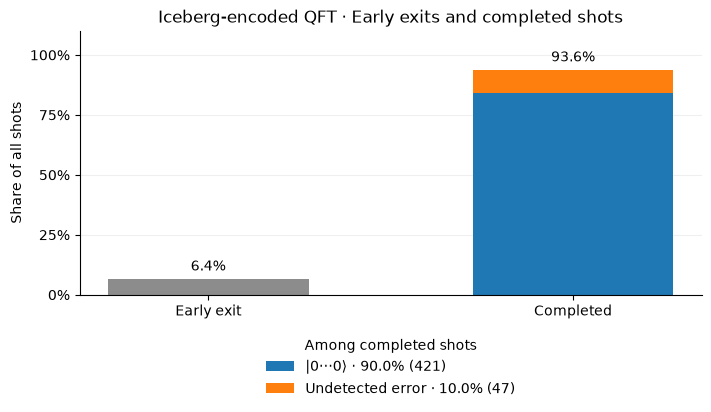

In [55]:
plot_exit_proportion(sys_result)

Finally, we will plot the proportion of completed shots which have the expected measurement outcome of "all $|0\rangle$". Successful shots are shown in green. Shots for which an undetected logical error occurs are shown in orange.

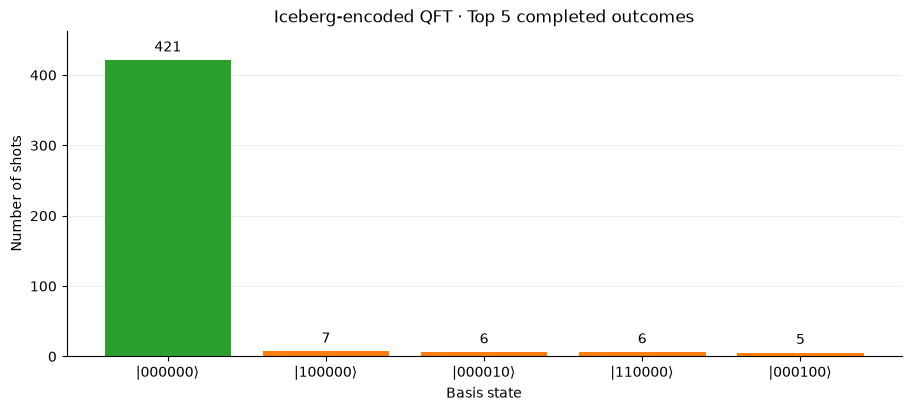

In [56]:
def plot_completed_shots(sys_result: QsysResult, n_strings: int) -> None:
    counts = sys_result.register_counts().get("m_x")
    top = counts.most_common(n_strings) if counts else []
    if not top:
        return

    states = [rf"$|{state}\rangle$" for state, _ in top]
    shots = [count for _, count in top]
    colors = ["tab:green"] + ["tab:orange"] * (len(shots) - 1)

    ax = _qft_axes(f"Top {len(top)} completed outcomes", "Number of shots", width=9)
    bars = ax.bar(states, shots, color=colors)
    ax.bar_label(bars, labels=[f"{count:,}" for count in shots], padding=4)
    ax.set(xlabel="Basis state", ylim=(0, 1.1 * max(shots)))
    plt.show()



plot_completed_shots(sys_result, n_strings=5)